# CICIDS2017 Explaining Your Detectors and Building a Belief Rule-Based Expert System Lab3

In [68]:
# Standard-library utilities for reproducibility, warnings, and project-relative paths.
import random
import warnings
from pathlib import Path

# Data handling, plotting, and model libraries.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score, confusion_matrix

# Fix random sources so that sampling, models, and explanations are repeatable.
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Install once with:
# %pip install shap lime
try:
    import shap
    from lime.lime_tabular import LimeTabularExplainer
    LAB3_EXPLAINERS_AVAILABLE = True
except ImportError:
    LAB3_EXPLAINERS_AVAILABLE = False
    print("SHAP/LIME are not installed. Run: %pip install shap lime")

## 1. Configure the experiment

In [69]:
# Resolve the data directory relative to the notebook's working directory.
project_dir = Path.cwd()
data_dir = project_dir / "data"

# Full-data runs are used for final results. Set USE_SAMPLE=True for a quicker smoke test.
USE_SAMPLE = False
SAMPLE_FRAC = 0.25

# Sorting makes the input order deterministic across operating systems.
csv_files = sorted(data_dir.glob("*.csv"))
print(f"Found {len(csv_files)} CSV files in data/")
for path in csv_files:
    print(" -", path.name)

Found 8 CSV files in data/
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv


## 2. Load and clean the CSV files

Used Latin-1 fallback for Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Cleaned dataset shape: (2813800, 81)

Dataset columns:
['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Pac

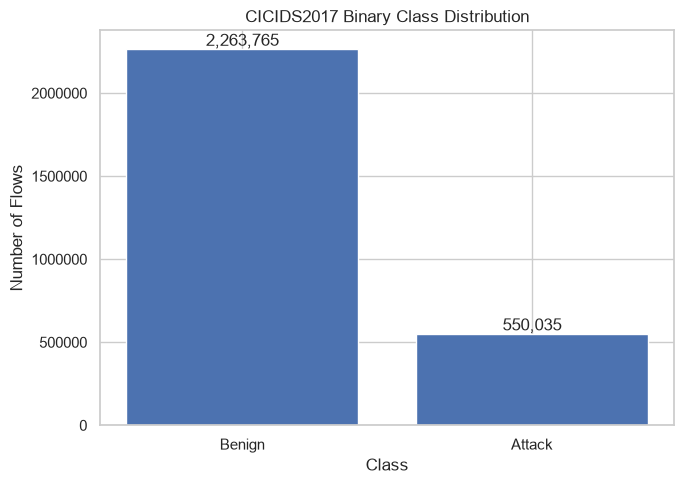

In [70]:
# Read every capture file and keep only files with a usable Label column.
# CICIDS2017 is distributed as several daily captures, so the files are combined into one experiment.
frames = []
for csv_path in csv_files:
    try:
        # UTF-8 handles the normal files; Latin-1 is a fallback for older CICIDS2017 exports.
        frame = pd.read_csv(csv_path, encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        frame = pd.read_csv(csv_path, encoding="latin1", low_memory=False)
        print(f"Used Latin-1 fallback for {csv_path.name}")

    # Header whitespace differs between source files, so normalize before locating Label.
    frame.columns = [str(col).strip() for col in frame.columns]
    label_col = next((col for col in frame.columns if col.lower() == "label"), None)
    if frame.empty or label_col is None:
        print(f"Skipping {csv_path.name}: no usable label column")
        continue
    if label_col != "Label":
        frame = frame.rename(columns={label_col: "Label"})
    frames.append(frame)

if not frames:
    raise ValueError("No valid CICIDS2017 CSV files were found in the data folder.")

# Combine captures into one flow-level dataset so both paradigms use identical observations.
df = pd.concat(frames, ignore_index=True)

# Remove identifiers and timestamps: they identify the capture context, but are not general traffic features.
metadata_cols = ["Flow ID", "Source IP", "Destination IP", "Timestamp"]
df = df.drop(columns=[col for col in metadata_cols if col in df.columns], errors="ignore")

# Deduplicate flows and convert invalid numeric values to missing values for pipeline imputation.
df = df.drop_duplicates().replace([np.inf, -np.inf], np.nan)
for col in df.columns:
    if col != "Label":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert multiclass attack names into the binary target required by the detectors:
# 0 represents BENIGN traffic and 1 represents every attack category.
df["Label"] = df["Label"].astype(str).str.strip().apply(lambda label: 0 if label == "BENIGN" else 1)
if USE_SAMPLE:
    # Sampling is optional for quick development; the final run uses all cleaned rows.
    df = df.sample(frac=SAMPLE_FRAC, random_state=SEED)

print("Cleaned dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())
print("\nLabel distribution:")
print(df["Label"].value_counts().sort_index())

# Visualize the class imbalance before model training.
label_counts = df["Label"].value_counts().sort_index()
plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["Benign", "Attack"],
    [label_counts.get(0, 0), label_counts.get(1, 0)],
)
plt.xlabel("Class")
plt.ylabel("Number of Flows")
plt.title("CICIDS2017 Binary Class Distribution")
plt.ticklabel_format(style="plain", axis="y")
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f"{int(height):,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 3. Create stratified train, validation, and test sets

In [71]:
# Separate features from the binary target before creating fixed experiment partitions.
X = df.drop(columns=["Label"])
y = df["Label"].astype(int)

# Keep the class ratio stable in all partitions: 60% train, 20% validation, and 20% test.
# The test partition stays untouched by model development and is also the source of explanation samples.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)
print("Train/validation/test sizes:", len(X_train), len(X_val), len(X_test))

Train/validation/test sizes: 1688280 562760 562760


## 4. Creating the 10% "few-label" splits

For the Lab 3 semi-supervised detector, only the **10% pseudo-labelling model** is trained below. This avoids rerunning models that are not needed for SHAP, LIME, or BRBES.

In [72]:
# Lab 3 compares one supervised detector with one semi-supervised detector.
LABEL_BUDGETS = [0.10]

# Build deterministic labelled and unlabelled pools from the same training partition.
few_label_splits = {}
for budget in LABEL_BUDGETS:
    # Stratification prevents the labelled subset from accidentally losing a class.
    X_labelled, X_unlabelled, y_labelled, _ = train_test_split(
        X_train,
        y_train,
        train_size=budget,
        random_state=SEED,
        stratify=y_train,
    )
    few_label_splits[budget] = {
        "X_labelled": X_labelled.copy(),
        "y_labelled": y_labelled.copy(),
        "X_unlabelled": X_unlabelled.copy(),
    }
    print(
        f"{budget:.0%} budget: "
        f"{len(X_labelled):,} labelled rows, "
        f"{len(X_unlabelled):,} unlabelled rows"
    )

# Validation and test partitions remain labelled so explanations can be checked against known outcomes.

10% budget: 168,828 labelled rows, 1,519,452 unlabelled rows


## 5. Train the supervised detector

The full-label Random Forest is the required supervised Lab 1 detector and will be explained with SHAP and LIME.

In [73]:
# Use one classifier and one preprocessing policy across both detectors.
def make_baseline_model():
    return Pipeline([
        # Fit imputation only on each method's training data to avoid validation leakage.
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        # Balanced class weights reduce the effect of the benign/attack imbalance.
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=SEED,
            class_weight="balanced",
            n_jobs=-1,
        )),
    ])

In [74]:
# Train the supervised detector on all available training labels.
full_label_model = make_baseline_model()
full_label_model.fit(X_train, y_train)
print("Supervised detector trained.")

Supervised detector trained.


## 6. Pseudo-Labelling

In [75]:
# A high confidence threshold limits error propagation, although some unlabelled rows may remain unused.
CONFIDENCE_THRESHOLD = 0.95
MAX_ROUNDS = 10


def pseudo_label_round(model, X_unlabelled, threshold):
    """Select unlabelled rows whose predicted class probability reaches the threshold."""
    probabilities = model.predict_proba(X_unlabelled)
    # The largest class probability becomes the pseudo-label confidence.
    predicted_labels = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)
    confident_mask = confidence >= threshold
    return X_unlabelled[confident_mask], predicted_labels[confident_mask], confident_mask


def run_pseudo_labelling(
    X_labelled,
    y_labelled,
    X_unlabelled,
    threshold=CONFIDENCE_THRESHOLD,
    max_rounds=MAX_ROUNDS,
):
    # Start with the small labelled set and grow it only with high-confidence predictions.
    X_train_growing = X_labelled.copy()
    y_train_growing = y_labelled.copy()
    X_pool_remaining = X_unlabelled.copy()
    round_history = []

    for round_num in range(1, max_rounds + 1):
        # Retraining after every round lets newly added labels influence the next selection.
        model = make_baseline_model()
        model.fit(X_train_growing, y_train_growing)

        if len(X_pool_remaining) == 0:
            break

        # Ask the current model which remaining unlabelled rows it can label confidently.
        X_confident, y_confident, confident_mask = pseudo_label_round(
            model, X_pool_remaining, threshold
        )
        round_history.append({
            "round": round_num,
            "labelled_pool_size": len(X_train_growing),
            "newly_pseudo_labelled": len(X_confident),
            "remaining_unlabelled": len(X_pool_remaining) - len(X_confident),
        })
        print(
            f"Round {round_num}: added {len(X_confident)} confident pseudo-labels "
            f"({len(X_pool_remaining) - len(X_confident)} unlabelled remain)"
        )

        # If no row meets the threshold, further rounds cannot change the training set.
        if len(X_confident) == 0:
            break

        # Add confident rows with their predicted labels, then remove them from the pool.
        X_train_growing = pd.concat([X_train_growing, X_confident], ignore_index=True)
        y_train_growing = np.concatenate([y_train_growing, y_confident])
        X_pool_remaining = X_pool_remaining[~confident_mask].reset_index(drop=True)

    # Fit once more on the complete labelled-plus-pseudo-labelled set used by the final detector.
    final_model = make_baseline_model()
    final_model.fit(X_train_growing, y_train_growing)
    return final_model, pd.DataFrame(round_history)

In [76]:
# Train the required semi-supervised detector with the 10% labelled split.
SEMI_SUPERVISED_BUDGET = 0.10
split = few_label_splits[SEMI_SUPERVISED_BUDGET]

print(f"--- Pseudo-labelling at {SEMI_SUPERVISED_BUDGET:.0%} label budget ---")
semi_supervised_model, pseudo_label_history = run_pseudo_labelling(
    split["X_labelled"].reset_index(drop=True),
    split["y_labelled"].reset_index(drop=True),
    split["X_unlabelled"].reset_index(drop=True),
    threshold=CONFIDENCE_THRESHOLD,
)

print("Pseudo-labelling history:")
display(pseudo_label_history)

# The two models required for this Lab 3 explanation study.
explain_models = {
    "Supervised": full_label_model,
    "Semi-supervised": semi_supervised_model,
}

--- Pseudo-labelling at 10% label budget ---
Round 1: added 1503724 confident pseudo-labels (15728 unlabelled remain)
Round 2: added 4789 confident pseudo-labels (10939 unlabelled remain)
Round 3: added 1319 confident pseudo-labels (9620 unlabelled remain)
Round 4: added 580 confident pseudo-labels (9040 unlabelled remain)
Round 5: added 397 confident pseudo-labels (8643 unlabelled remain)
Round 6: added 322 confident pseudo-labels (8321 unlabelled remain)
Round 7: added 240 confident pseudo-labels (8081 unlabelled remain)
Round 8: added 133 confident pseudo-labels (7948 unlabelled remain)
Round 9: added 124 confident pseudo-labels (7824 unlabelled remain)
Round 10: added 102 confident pseudo-labels (7722 unlabelled remain)
Pseudo-labelling history:


,round,labelled_pool_size,newly_pseudo_labelled,remaining_unlabelled
0,1,168828,1503724,15728
1,2,1672552,4789,10939
2,3,1677341,1319,9620
3,4,1678660,580,9040
4,5,1679240,397,8643
5,6,1679637,322,8321
6,7,1679959,240,8081
7,8,1680199,133,7948
8,9,1680332,124,7824
9,10,1680456,102,7722


## 7. Step 2 - Explain both detectors with SHAP

SHAP is run on the same held-out samples for both models. The bar and beeswarm plots show global feature importance, while the waterfall plots show why individual predictions were classified as benign or attack.

Global SHAP sample shape: (400, 80)
Global SHAP class distribution:
Label
0    200
1    200
Name: count, dtype: int64

Local explanation sample shape: (3, 80)
Local explanation labels:
[1, 1, 0]
Supervised: global SHAP importance


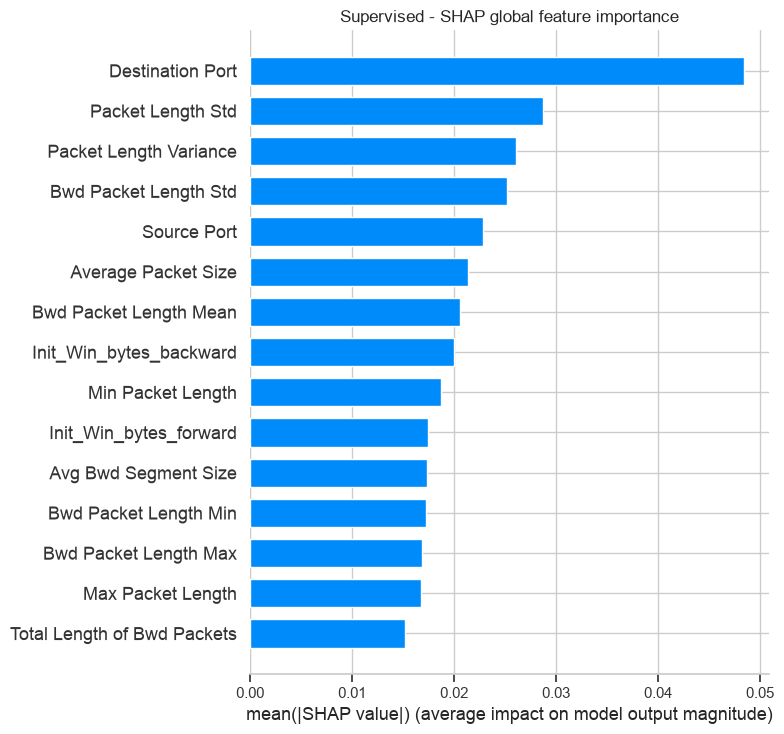

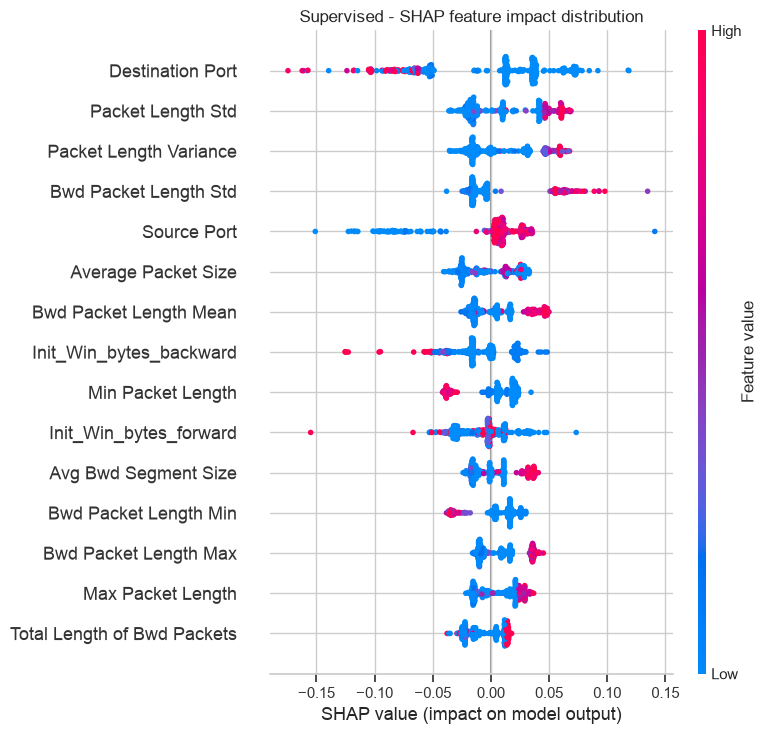

Supervised: local SHAP explanations
Sample 1: true label=1, predicted label=1


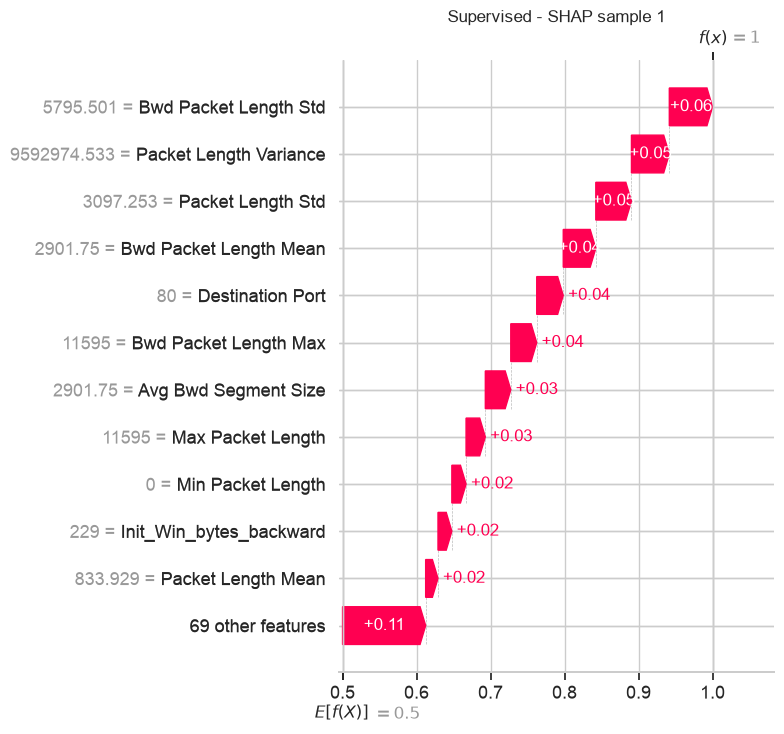

Sample 2: true label=1, predicted label=1


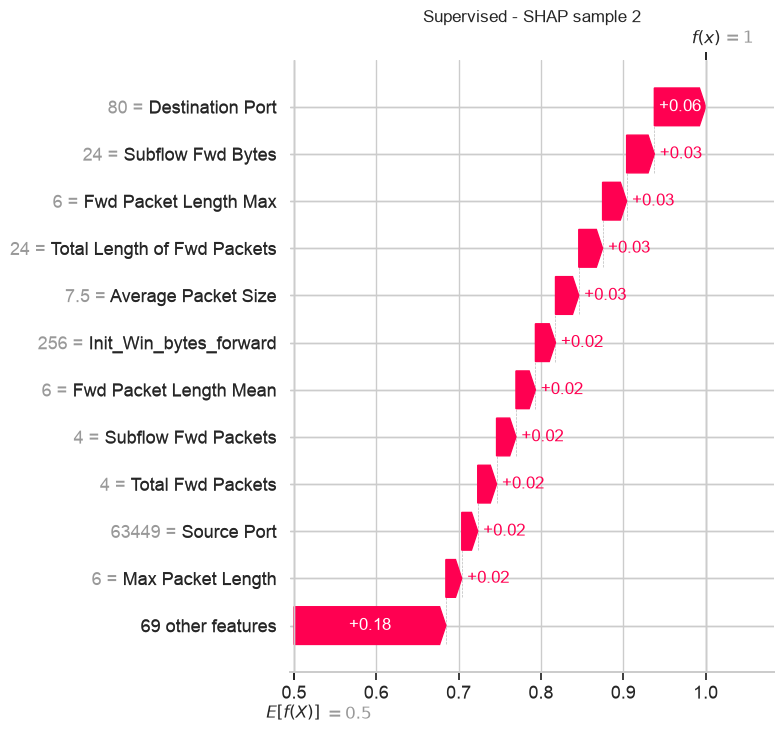

Sample 3: true label=0, predicted label=0


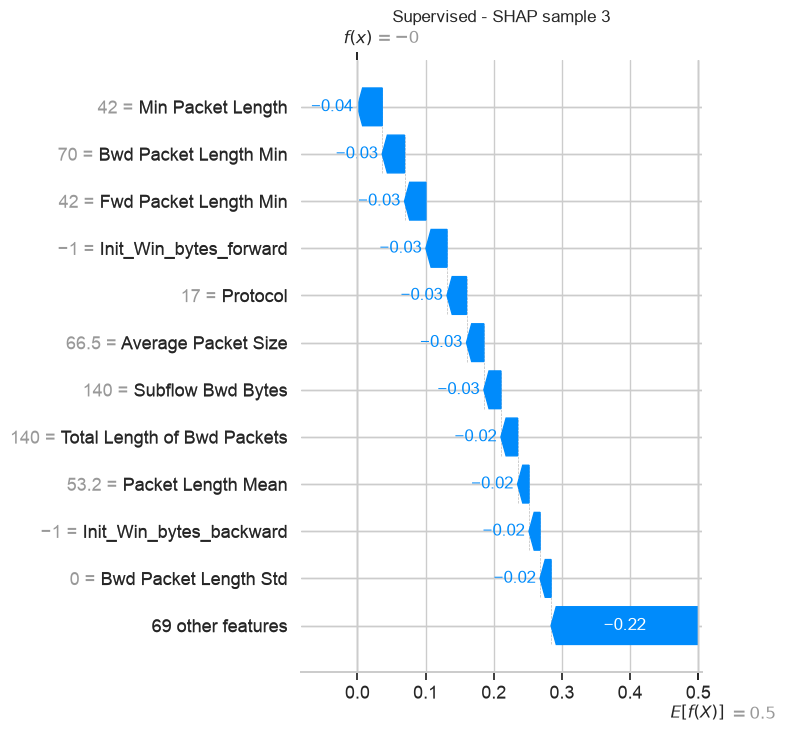

Semi-supervised: global SHAP importance


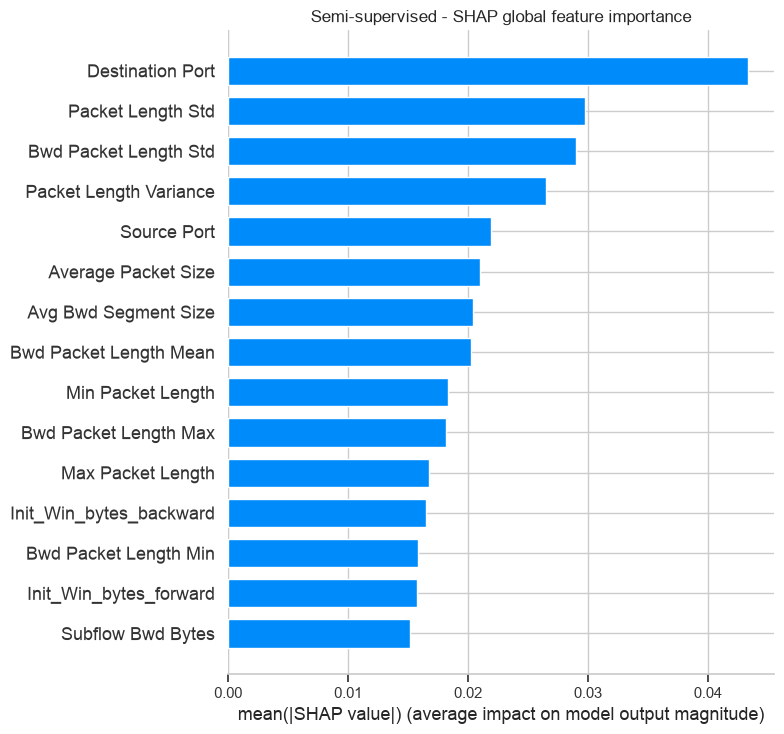

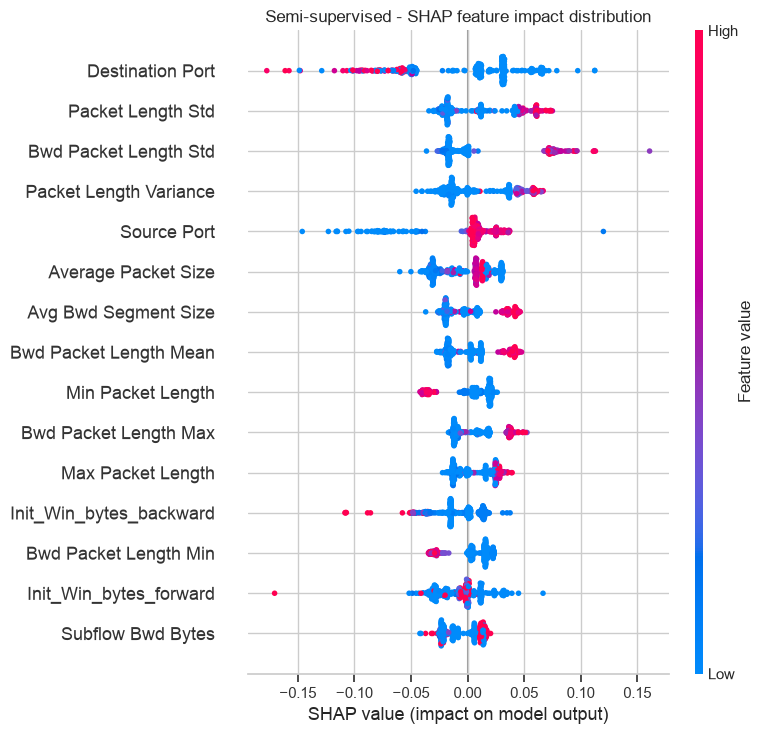

Semi-supervised: local SHAP explanations
Sample 1: true label=1, predicted label=1


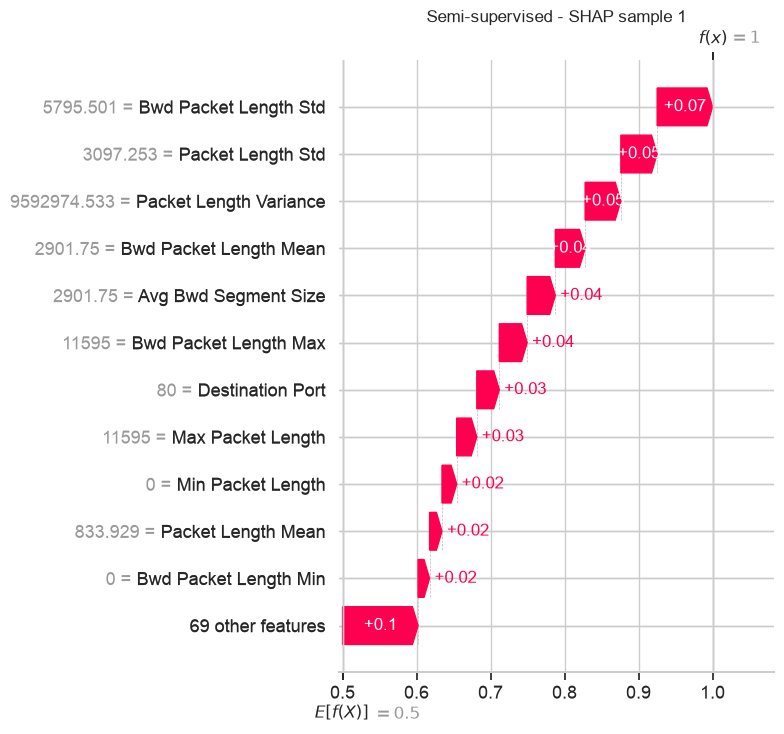

Sample 2: true label=1, predicted label=1


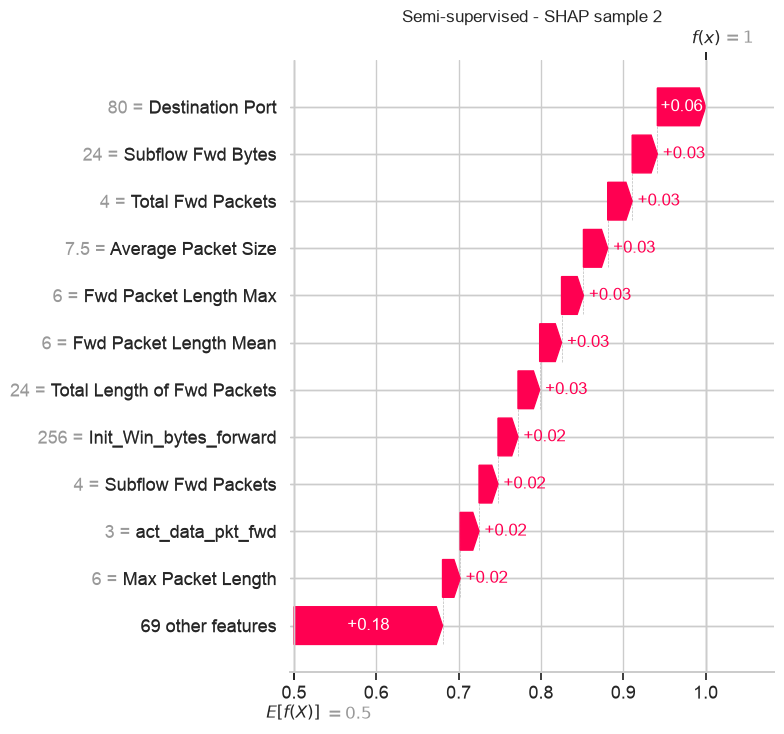

Sample 3: true label=0, predicted label=0


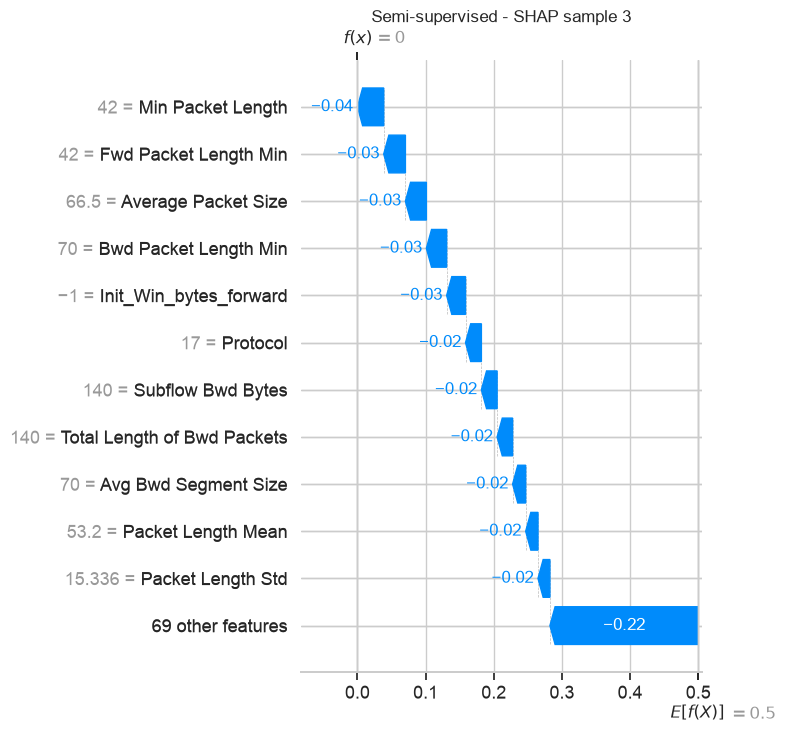

In [77]:
# Create balanced global and deliberately class-covered local samples for SHAP and LIME.
# The global sample gives a stable feature ranking without explaining every test row.
# The local sample is reused by SHAP waterfalls and LIME so the methods are directly comparable.
SHAP_GLOBAL_PER_CLASS = 200

benign_global_idx = y_test[y_test == 0].sample(
    n=SHAP_GLOBAL_PER_CLASS,
    random_state=SEED,
).index
attack_global_idx = y_test[y_test == 1].sample(
    n=SHAP_GLOBAL_PER_CLASS,
    random_state=SEED,
).index

global_indices = benign_global_idx.union(attack_global_idx)
X_shap_global = X_test.loc[global_indices].copy()
y_shap_global = y_test.loc[global_indices].copy()

# Mix the two classes so the sample is not ordered by label.
global_order = np.random.RandomState(SEED).permutation(len(X_shap_global))
X_shap_global = X_shap_global.iloc[global_order].reset_index(drop=True)
y_shap_global = y_shap_global.iloc[global_order].reset_index(drop=True)

# Select one benign and two attack flows so local explanations always cover both classes.
benign_local_idx = y_test[y_test == 0].sample(n=1, random_state=SEED).index
attack_local_idx = y_test[y_test == 1].sample(n=2, random_state=SEED).index
local_indices = benign_local_idx.union(attack_local_idx)
X_explanation = X_test.loc[local_indices].reset_index(drop=True)
y_explanation = y_test.loc[local_indices].reset_index(drop=True)

print("Global SHAP sample shape:", X_shap_global.shape)
print("Global SHAP class distribution:")
print(y_shap_global.value_counts().sort_index())
print("\nLocal explanation sample shape:", X_explanation.shape)
print("Local explanation labels:")
print(y_explanation.tolist())


def make_shap_explanation(pipeline, X_rows):
    """Explain attack probability after applying the pipeline's fitted imputer."""
    imputer = pipeline.named_steps["imputer"]
    forest = pipeline.named_steps["model"]
    transformed_rows = imputer.transform(X_rows)
    raw_explanation = shap.TreeExplainer(forest)(transformed_rows)

    # SHAP can return one contribution matrix per class; class 1 is the attack class.
    if raw_explanation.values.ndim == 3:
        values = raw_explanation.values[:, :, 1]
        base_values = raw_explanation.base_values[:, 1]
    else:
        values = raw_explanation.values
        base_values = raw_explanation.base_values

    return shap.Explanation(
        values=values,
        base_values=base_values,
        data=transformed_rows,
        feature_names=list(X_rows.columns),
    )


shap_global_explanations = {}
shap_local_explanations = {}
for paradigm, model in explain_models.items():
    # Use the balanced sample for global importance and the shared rows for local explanations.
    global_explanation = make_shap_explanation(model, X_shap_global)
    local_explanation = make_shap_explanation(model, X_explanation)
    shap_global_explanations[paradigm] = global_explanation
    shap_local_explanations[paradigm] = local_explanation

    # Mean absolute SHAP values rank features by their average effect across both classes.
    print(f"{paradigm}: global SHAP importance")
    shap.summary_plot(
        global_explanation.values,
        global_explanation.data,
        feature_names=global_explanation.feature_names,
        plot_type="bar",
        max_display=15,
        show=False,
    )
    plt.title(f"{paradigm} - SHAP global feature importance")
    plt.tight_layout()
    plt.show()

    # The beeswarm plot adds direction: positive values push toward attack, negative toward benign.
    shap.summary_plot(
        global_explanation.values,
        global_explanation.data,
        feature_names=global_explanation.feature_names,
        max_display=15,
        show=False,
    )
    plt.title(f"{paradigm} - SHAP feature impact distribution")
    plt.tight_layout()
    plt.show()

    # Waterfalls show the feature contributions for the same three flows later explained by LIME.
    print(f"{paradigm}: local SHAP explanations")
    for row_number in range(len(X_explanation)):
        predicted_label = int(model.predict(X_explanation.iloc[[row_number]])[0])
        print(
            f"Sample {row_number + 1}: true label={int(y_explanation.iloc[row_number])}, "
            f"predicted label={predicted_label}"
        )
        shap.plots.waterfall(
            local_explanation[row_number],
            max_display=12,
            show=False,
        )
        plt.title(f"{paradigm} - SHAP sample {row_number + 1}")
        plt.tight_layout()
        plt.show()

## 8. Step 3 - Explain both detectors with LIME

LIME uses the same three held-out samples as SHAP. Each local explanation lists the feature ranges that push the prediction toward attack or benign, allowing the two explanation methods to be compared on identical cases.

In [78]:
# LIME needs numeric arrays, while the fitted pipeline expects DataFrames with feature names.
# The imputed training data defines the perturbation distribution used by both LIME explainers.
lime_background = explain_models["Supervised"].named_steps["imputer"].transform(X_train)
feature_names = list(X_train.columns)

lime_explainers = {}
for paradigm in explain_models:
    lime_explainers[paradigm] = LimeTabularExplainer(
        training_data=lime_background,
        feature_names=feature_names,
        class_names=["Benign", "Attack"],
        mode="classification",
        discretize_continuous=True,
        random_state=SEED,
    )


def lime_predict_proba(model, feature_array):
    """Adapt LIME's NumPy input to the DataFrame expected by the fitted pipeline."""
    feature_frame = pd.DataFrame(feature_array, columns=feature_names)
    return model.predict_proba(feature_frame)


lime_results = []
for paradigm, model in explain_models.items():
    print(f"{paradigm}: LIME local explanations")
    explainer = lime_explainers[paradigm]
    for row_number in range(len(X_explanation)):
        # Explain exactly the same held-out flow used in the corresponding SHAP waterfall.
        row_array = model.named_steps["imputer"].transform(X_explanation.iloc[[row_number]])[0]
        lime_explanation = explainer.explain_instance(
            row_array,
            lambda values: lime_predict_proba(model, values),
            labels=[1],
            num_features=10,
            num_samples=1000,
        )
        local_contributions = lime_explanation.as_list(label=1)
        predicted_label = int(model.predict(X_explanation.iloc[[row_number]])[0])
        print(
            f"Sample {row_number + 1}: true label={int(y_explanation.iloc[row_number])}, "
            f"predicted label={predicted_label}"
        )
        # LIME weights are local surrogate coefficients: positive means attack, negative means benign.
        for feature_rule, contribution in local_contributions:
            direction = "toward attack" if contribution > 0 else "toward benign"
            print(f"  {contribution:+.4f} {direction}: {feature_rule}")
        lime_results.append({
            "paradigm": paradigm,
            "sample": row_number + 1,
            "true_label": int(y_explanation.iloc[row_number]),
            "predicted_label": predicted_label,
            "attack_contributions": [
                {"feature_rule": rule, "weight": float(weight)}
                for rule, weight in local_contributions
                if weight > 0
            ],
            "benign_contributions": [
                {"feature_rule": rule, "weight": float(weight)}
                for rule, weight in local_contributions
                if weight < 0
            ],
        })

# Keep a compact table for reporting while retaining the full contribution lists above.
lime_results_df = pd.DataFrame(lime_results)
display(lime_results_df[["paradigm", "sample", "true_label", "predicted_label"]])

Supervised: LIME local explanations
Sample 1: true label=1, predicted label=1
  +0.0411 toward attack: 53.00 < Destination Port <= 80.00
  +0.0279 toward attack: Bwd Packet Length Min <= 0.00
  +0.0268 toward attack: 2.00 < Subflow Bwd Packets <= 4.00
  +0.0263 toward attack: Protocol <= 6.00
  +0.0254 toward attack: 2.00 < Total Backward Packets <= 4.00
  -0.0245 toward benign: ECE Flag Count <= 0.00
  +0.0201 toward attack: Min Packet Length <= 0.00
  +0.0186 toward attack: Idle Std > 0.00
  +0.0148 toward attack: Idle Mean > 0.00
  +0.0138 toward attack: Fwd IAT Std > 69977.12
Sample 2: true label=1, predicted label=1
  +0.0378 toward attack: 53.00 < Destination Port <= 80.00
  +0.0252 toward attack: Protocol <= 6.00
  +0.0204 toward attack: Bwd Packet Length Min <= 0.00
  +0.0163 toward attack: 64.00 < Fwd Header Length.1 <= 120.00
  +0.0162 toward attack: Source Port > 58482.00
  +0.0131 toward attack: Max Packet Length <= 6.00
  +0.0110 toward attack: Subflow Bwd Bytes <= 6.00
  

,paradigm,sample,true_label,predicted_label
0,Supervised,1,1,1
1,Supervised,2,1,1
2,Supervised,3,0,0
3,Semi-supervised,1,1,1
4,Semi-supervised,2,1,1
5,Semi-supervised,3,0,0


## 9. Step 4 - Compare SHAP and LIME explanations

We compare both methods for each detector on three criteria:

- **Faithfulness:** masking the top-ranked features should noticeably change the model's attack probability.
- **Stability:** repeated explanations should select similar important features for the same flow.
- **Readability:** the explanation format should be understandable to a human analyst.

The faithfulness and stability checks below are empirical checks on this sample, not guarantees for every future flow.

In [79]:
# The masking test measures how much the model's attack probability changes when
# the features selected by an explanation are replaced by training medians.
# A larger change means the selected features had stronger influence on that prediction.
comparison_rows = []
training_medians = X_train.median(numeric_only=True)


def mask_and_measure(model, X_row, selected_features):
    """Return the absolute attack-probability change after masking selected features."""
    selected_features = [
        feature for feature in selected_features
        if feature in X_row.columns and feature in training_medians.index
    ]
    original_probability = float(model.predict_proba(X_row)[0, 1])
    masked_row = X_row.copy()
    for feature in selected_features:
        masked_row.loc[:, feature] = training_medians[feature]
    masked_probability = float(model.predict_proba(masked_row)[0, 1])
    return abs(original_probability - masked_probability)


def feature_from_lime_rule(rule, available_features):
    """Recover the feature name contained in a human-readable LIME interval."""
    matches = [feature for feature in available_features if feature in rule]
    return max(matches, key=len) if matches else None


for paradigm, model in explain_models.items():
    shap_explanation = shap_local_explanations[paradigm]
    for row_number in range(len(X_explanation)):
        # SHAP ranks the local features by absolute contribution to attack probability.
        shap_order = np.argsort(
            -np.abs(shap_explanation.values[row_number])
        )
        shap_features = [
            shap_explanation.feature_names[index]
            for index in shap_order[:5]
        ]
        shap_delta = mask_and_measure(
            model,
            X_explanation.iloc[[row_number]],
            shap_features,
        )

        # LIME rules contain intervals such as "53 < Destination Port <= 80".
        # Map those readable rules back to their original feature columns for masking.
        lime_record = next(
            record for record in lime_results
            if record["paradigm"] == paradigm and record["sample"] == row_number + 1
        )
        lime_rules = lime_record["attack_contributions"] + lime_record["benign_contributions"]
        lime_features = []
        for item in sorted(lime_rules, key=lambda item: abs(item["weight"]), reverse=True):
            feature = feature_from_lime_rule(item["feature_rule"], feature_names)
            if feature and feature not in lime_features:
                lime_features.append(feature)
            if len(lime_features) == 5:
                break
        lime_delta = mask_and_measure(
            model,
            X_explanation.iloc[[row_number]],
            lime_features,
        )

        comparison_rows.extend([
            {
                "paradigm": paradigm,
                "method": "SHAP",
                "sample": row_number + 1,
                "top_features": ", ".join(shap_features),
                "masked_probability_change": shap_delta,
            },
            {
                "paradigm": paradigm,
                "method": "LIME",
                "sample": row_number + 1,
                "top_features": ", ".join(lime_features),
                "masked_probability_change": lime_delta,
            },
        ])

faithfulness_results_df = pd.DataFrame(comparison_rows)
print("Faithfulness check: larger probability changes indicate stronger local influence.")
display(faithfulness_results_df.round(4))

Faithfulness check: larger probability changes indicate stronger local influence.


,paradigm,method,sample,top_features,masked_probability_change
0,Supervised,SHAP,1,"Bwd Packet Length Std, Packet Length Variance,...",0.3900
1,Supervised,LIME,1,"Destination Port, Bwd Packet Length Min, Subfl...",0.0100
2,Supervised,SHAP,2,"Destination Port, Subflow Fwd Bytes, Fwd Packe...",0.4600
3,Supervised,LIME,2,"Destination Port, Protocol, Bwd Packet Length ...",0.0400
4,Supervised,SHAP,3,"Min Packet Length, Bwd Packet Length Min, Fwd ...",0.3833
5,Supervised,LIME,3,"Destination Port, Protocol, Min Packet Length,...",0.2833
6,Semi-supervised,SHAP,1,"Bwd Packet Length Std, Packet Length Std, Pack...",0.5333
7,Semi-supervised,LIME,1,"Destination Port, Subflow Bwd Packets, ECE Fla...",0.0133
8,Semi-supervised,SHAP,2,"Destination Port, Subflow Fwd Bytes, Total Fwd...",0.5333
9,Semi-supervised,LIME,2,"Destination Port, Protocol, Fwd Header Length....",0.0433


In [80]:
# Stability compares the top five feature names from two independent explanation runs.
# SHAP is deterministic here because the fitted tree model and input are fixed.
# LIME is stochastic, so it is rerun with a different random seed.

def top_lime_features(model, row_array, random_state):
    """Return unique LIME feature names ordered by absolute local weight."""
    repeated_explainer = LimeTabularExplainer(
        training_data=lime_background,
        feature_names=feature_names,
        class_names=["Benign", "Attack"],
        mode="classification",
        discretize_continuous=True,
        random_state=random_state,
    )
    repeated_explanation = repeated_explainer.explain_instance(
        row_array,
        lambda values: lime_predict_proba(model, values),
        labels=[1],
        num_features=10,
        num_samples=1000,
    )
    selected = []
    ranked_rules = sorted(
        repeated_explanation.as_list(label=1),
        key=lambda item: abs(item[1]),
        reverse=True,
    )
    for rule, _ in ranked_rules:
        feature = feature_from_lime_rule(rule, feature_names)
        if feature and feature not in selected:
            selected.append(feature)
        if len(selected) == 5:
            break
    return selected


def overlap_score(first_features, second_features):
    """Return top-five set overlap, where 1.0 means identical feature sets."""
    first_set = set(first_features)
    second_set = set(second_features)
    union = first_set | second_set
    return len(first_set & second_set) / len(union) if union else 1.0


stability_rows = []
for paradigm, model in explain_models.items():
    shap_explanation = shap_local_explanations[paradigm]
    for row_number in range(len(X_explanation)):
        shap_order = np.argsort(-np.abs(shap_explanation.values[row_number]))
        shap_first = [
            shap_explanation.feature_names[index]
            for index in shap_order[:5]
        ]
        shap_second = [
            shap_explanation.feature_names[index]
            for index in shap_order[:5]
        ]
        stability_rows.append({
            "paradigm": paradigm,
            "method": "SHAP",
            "sample": row_number + 1,
            "top_feature_overlap": overlap_score(shap_first, shap_second),
        })

        row_array = model.named_steps["imputer"].transform(
            X_explanation.iloc[[row_number]]
        )[0]
        lime_first = top_lime_features(model, row_array, SEED)
        lime_second = top_lime_features(model, row_array, SEED + 1)
        stability_rows.append({
            "paradigm": paradigm,
            "method": "LIME",
            "sample": row_number + 1,
            "top_feature_overlap": overlap_score(lime_first, lime_second),
        })

stability_results_df = pd.DataFrame(stability_rows)
print("Stability check: 1.0 means the repeated runs selected the same top features.")
display(stability_results_df.round(4))

Stability check: 1.0 means the repeated runs selected the same top features.


,paradigm,method,sample,top_feature_overlap
0,Supervised,SHAP,1,1.0000
1,Supervised,LIME,1,0.6667
2,Supervised,SHAP,2,1.0000
3,Supervised,LIME,2,0.4286
4,Supervised,SHAP,3,1.0000
5,Supervised,LIME,3,0.6667
6,Semi-supervised,SHAP,1,1.0000
7,Semi-supervised,LIME,1,0.4286
8,Semi-supervised,SHAP,2,1.0000
9,Semi-supervised,LIME,2,0.6667


### Interpretation of the comparison

The numerical tables above provide the empirical faithfulness and stability evidence for this sample. Readability is assessed qualitatively because it depends on the analyst's ability to understand the output:

| Criterion | SHAP | LIME |
|---|---|---|
| Faithfulness | Uses exact tree-model contributions and supports global and local views. | Uses a local surrogate; faithfulness depends on the perturbation sample and local fit. |
| Stability | Deterministic for the fixed Random Forest and input rows. | Can vary between runs because it samples perturbed inputs. |
| Readability | Waterfalls are detailed and technically precise, but can be dense. | Feature intervals and signed weights are compact and easy to scan. |

Agreement is strongest when both methods identify the same feature and direction, for example a feature pushing a sample toward attack. Disagreement is expected when correlated features share influence or when LIME's local surrogate approximates a nonlinear tree decision poorly. The masking and overlap tables should be used to report the observed agreement for this run rather than assuming that either method is always superior.

## Step 5: Select the top two features

In [81]:
# Extract the two most important SHAP features for each paradigm.
top_shap_features = {}
for paradigm, explanation in shap_global_explanations.items():
    # Mean absolute SHAP values rank features by their average effect across both classes.
    mean_abs_values = np.mean(np.abs(explanation.values), axis=0)
    # DataFrame holds the feature names and their corresponding mean absolute SHAP values, sorted in descending order of importance.
    importance_df = pd.DataFrame({
        "feature": explanation.feature_names,
        "mean_abs_shap": mean_abs_values,
    }).sort_values(by="mean_abs_shap", ascending=False)
    # Keep only the top two features for later BRBES implementation and reporting.
    top_shap_features[paradigm] = importance_df["feature"].head(2).tolist()

    print(f"{paradigm}: top two SHAP features")
    display(importance_df.head(10).round(4))
print("Top SHAP features for BRBES implementation:", top_shap_features)

Supervised: top two SHAP features


,feature,mean_abs_shap
1,Destination Port,0.0484
43,Packet Length Std,0.0287
44,Packet Length Variance,0.0261
15,Bwd Packet Length Std,0.0251
0,Source Port,0.0228
54,Average Packet Size,0.0213
14,Bwd Packet Length Mean,0.0206
69,Init_Win_bytes_backward,0.0200
40,Min Packet Length,0.0188
68,Init_Win_bytes_forward,0.0174


Semi-supervised: top two SHAP features


,feature,mean_abs_shap
1,Destination Port,0.0434
43,Packet Length Std,0.0297
15,Bwd Packet Length Std,0.0290
44,Packet Length Variance,0.0265
0,Source Port,0.0219
54,Average Packet Size,0.0210
56,Avg Bwd Segment Size,0.0205
14,Bwd Packet Length Mean,0.0203
40,Min Packet Length,0.0184
12,Bwd Packet Length Max,0.0181


Top SHAP features for BRBES implementation: {'Supervised': ['Destination Port', 'Packet Length Std'], 'Semi-supervised': ['Destination Port', 'Packet Length Std']}


In [82]:
# Check if the selected top SHAP features appear in local LIME
lime_support_rows = []
# Compare the top SHAP features with the LIME-selected features for each paradigm and sample.
for paradigm, selected_features in top_shap_features.items():
    lime_rows = lime_results_df[lime_results_df["paradigm"] == paradigm]
    for _, row in lime_rows.iterrows():
        sample_number = row["sample"]
        # Map the human-readable LIME rules back to their original feature names for comparison with SHAP.
        lime_attack_features = [
            feature_from_lime_rule(item["feature_rule"], feature_names)
            for item in row["attack_contributions"]
        ]
        lime_benign_features = [
            feature_from_lime_rule(item["feature_rule"], feature_names)
            for item in row["benign_contributions"]
        ]
        # Combine the attack and benign features selected by LIME into a single set for comparison.
        lime_selected_features = set(lime_attack_features + lime_benign_features)
        shap_selected_features = set(selected_features)
        # Calculate the overlap between the top SHAP features and the LIME-selected features.
        overlap = shap_selected_features.intersection(lime_selected_features)
        # Store the comparison results in a structured format for reporting.
        lime_support_rows.append({
            "paradigm": paradigm,
            "sample": sample_number,
            "shap_top_features": ", ".join(selected_features),
            "lime_top_features": ", ".join(lime_selected_features),
            "overlap_count": len(overlap),
            "overlap_features": ", ".join(overlap) if overlap else "",
        })
lime_support_df = pd.DataFrame(lime_support_rows)
display(lime_support_df)

,paradigm,sample,shap_top_features,lime_top_features,overlap_count,overlap_features
0,Supervised,1,"Destination Port, Packet Length Std","Bwd Packet Length Min, ECE Flag Count, Min Pac...",1,Destination Port
1,Supervised,2,"Destination Port, Packet Length Std","Flow IAT Std, Bwd Packet Length Std, Fwd Heade...",1,Destination Port
2,Supervised,3,"Destination Port, Packet Length Std","Active Std, Bwd Packet Length Min, Fwd Packet ...",1,Destination Port
3,Semi-supervised,1,"Destination Port, Packet Length Std","Fwd IAT Mean, SYN Flag Count, Bwd Packet Lengt...",1,Destination Port
4,Semi-supervised,2,"Destination Port, Packet Length Std","Flow IAT Std, Fwd Header Length.1, Bwd Packet ...",1,Destination Port
5,Semi-supervised,3,"Destination Port, Packet Length Std","SYN Flag Count, Bwd Packet Length Min, Fwd Pac...",1,Destination Port


### Step 5 conclusion

The feature selection for BRBES are based on the results from the SHAP analysis.
The global SHAP ranking selected Destination Port and Packet Length Std as the two most important features for both the supervised and semi-supervised models. Bwd Packet Length Std was the third-ranked feature for the semi-supervised detector.
These features was then checked against the local LIME explanations. As seen in the table above the destination port appeared in all three local Lime explanations for the supervised learning, while the packet length did not appear among the local Lime explanations.
For the semi-supervised model both our features from the SHAP analysis appeared in the local LIME explanation.
This partial disagreement we could see for the supervised model is not unexpected, since SHAP ranks the features using global importance across the balanced evalutation sample, while LIME explains it locally.
The feature selection for BRBES is therefore based on the gliabl SHAP ranking and we're using LIME as a local consistence check.

## Step 6: Build a belief rule base for each model

We now convert the two SHAP-ranked features for each detector into a compact belief rule base (BRB). Each feature is discretized into Low, Medium, and High states using training quantiles. For each feature-state combination, we estimate the empirical belief that the flow belongs to the benign or attack class. The resulting BRB provides an interpretable decision layer that can be evaluated on the same held-out samples used in the earlier explanation study.


In [83]:
# Build a belief rule base (BRBES) from the two top SHAP features for each model.
# The lab requires five inference ideas: knowledge representation, input transformation,
# rule activation, belief update, and Evidential Reasoning (ER) aggregation.
# Each rule therefore stores theta (rule weight), delta (attribute weights), and
# a belief distribution over Low/Medium/High attack risk.


def membership_degrees(value, thresholds):
    """Transform one numeric value into matching degrees over Low, Medium, and High."""
    q1, q2 = thresholds
    if pd.isna(value):
        # A missing value supplies no evidence; the inference step preserves this as ignorance.
        return {"Low": 0.0, "Medium": 0.0, "High": 0.0}
    if value <= q1:
        return {"Low": 1.0, "Medium": 0.0, "High": 0.0}
    if value <= q2:
        fraction = (value - q1) / (q2 - q1) if q2 > q1 else 0.5
        return {"Low": 1.0 - fraction, "Medium": fraction, "High": 0.0}
    return {"Low": 0.0, "Medium": 0.0, "High": 1.0}


def feature_state(value, thresholds):
    """Return the strongest Low/Medium/High state for displaying a rule match."""
    return max(membership_degrees(value, thresholds), key=membership_degrees(value, thresholds).get)


def build_brb(X_train_subset, y_train_subset, features):
    """Create a complete data-derived rule base with theta, delta, and risk beliefs."""
    thresholds = {}
    for feature in features:
        values = X_train_subset[feature].fillna(X_train_subset[feature].median())
        #divide the numeric range into three equal-sized quantiles for Low/Medium/High risk. 
        # Choosing 0.33 and 0.67 ensures that the middle quantile is not empty even for small training subsets.
        q1, q2 = values.quantile([0.33, 0.67]).tolist()
        thresholds[feature] = (q1, q2)

    # Count benign and attack flows for every observed input-state combination.
    rule_counts = {}
    for idx, row in X_train_subset[features].fillna(X_train_subset[features].median()).iterrows():
        state_tuple = tuple(
            feature_state(row[feature], thresholds[feature])
            for feature in features
        )
        label = int(y_train_subset.loc[idx])
        rule_counts.setdefault(state_tuple, {"Benign": 0, "Attack": 0})
        class_name = "Attack" if label == 1 else "Benign"
        rule_counts[state_tuple][class_name] += 1

    # With two three-level antecedents there are 3 x 3 = 9 possible combinations.
    # Empty combinations remain explicit rules with complete ignorance rather than disappearing.
    levels = ["Low", "Medium", "High"]
    all_combinations = [
        (first_state, second_state)
        for first_state in levels
        for second_state in levels
    ]
    rule_base = {}
    for state_tuple in all_combinations:
        counts = rule_counts.get(state_tuple, {"Benign": 0, "Attack": 0})
        total = sum(counts.values())
        attack_share = counts["Attack"] / total if total else 0.0

        # Convert the attack share into a three-level risk distribution.
        # p below 0.5 gives Low/Medium risk; p above 0.5 gives Medium/High risk.
        beliefs = {
            "Low": max(0.0, 1.0 - 2.0 * attack_share),
            "Medium": 1.0 - abs(2.0 * attack_share - 1.0),
            "High": max(0.0, 2.0 * attack_share - 1.0),
        }
        if total == 0:
            beliefs = {"Low": 0.0, "Medium": 0.0, "High": 0.0}

        rule_base[state_tuple] = {
            "beliefs": beliefs,
            # No expert preference was supplied, so all rules start equally weighted.
            "rule_weight": 1.0,
            "attribute_weights": {feature: 1.0 for feature in features},
            "counts": counts,
        }
    return thresholds, rule_base


def evaluate_brb(sample_row, thresholds, rule_base, features):
    """Run input transformation, activation, belief update, ER aggregation, and decision."""
    input_degrees = {
        feature: membership_degrees(sample_row[feature], thresholds[feature])
        for feature in features
    }

    # Rule activation: combine matching degrees with theta and delta, then normalize.
    activations = {}
    for state_tuple, rule in rule_base.items():
        activation = rule["rule_weight"]
        for feature, state in zip(features, state_tuple):
            delta = rule["attribute_weights"][feature]
            activation *= input_degrees[feature][state] ** delta
        activations[state_tuple] = activation
    activation_total = sum(activations.values())
    if activation_total == 0:
        return {
            "beliefs": {"Low": 0.0, "Medium": 0.0, "High": 0.0, "Ignorance": 1.0},
            "utility": 50.0,
            "predicted_label": "Benign",
        }
    activations = {key: value / activation_total for key, value in activations.items()}

    # Belief update and ER aggregation. Missing features reduce committed belief;
    # the remaining mass is kept explicitly as ignorance.
    aggregate = {"Low": 0.0, "Medium": 0.0, "High": 0.0, "Ignorance": 1.0}
    for state_tuple, activation in activations.items():
        rule = rule_base[state_tuple]
        completeness = sum(bool(input_degrees[feature]) for feature in features) / len(features)
        discounted = {
            level: activation * completeness * rule["beliefs"][level]
            for level in ["Low", "Medium", "High"]
        }
        discounted["Ignorance"] = 1.0 - sum(discounted.values())

        # Combine singleton belief masses and ignorance using an ER-style conjunctive update.
        combined = {"Low": 0.0, "Medium": 0.0, "High": 0.0, "Ignorance": 0.0}
        conflict = 0.0
        for old_level, old_mass in aggregate.items():
            for new_level, new_mass in discounted.items():
                if old_level != "Ignorance" and new_level != "Ignorance" and old_level != new_level:
                    conflict += old_mass * new_mass
                elif old_level == "Ignorance" and new_level == "Ignorance":
                    combined["Ignorance"] += old_mass * new_mass
                elif old_level == "Ignorance":
                    combined[new_level] += old_mass * new_mass
                elif new_level == "Ignorance":
                    combined[old_level] += old_mass * new_mass
                else:
                    combined[old_level] += old_mass * new_mass
        normalizer = max(1.0 - conflict, 1e-12)
        aggregate = {level: mass / normalizer for level, mass in combined.items()}

    # Convert the final risk beliefs into the lab's suggested utility score.
    utility = 0.0 * aggregate["Low"] + 50.0 * aggregate["Medium"] + 100.0 * aggregate["High"]
    return {
        "beliefs": aggregate,
        "utility": utility,
        "predicted_label": "Attack" if utility >= 50.0 else "Benign",
    }


# Build one BRBES for each required learning paradigm using its own SHAP-selected features.
brb_models = {}
brb_summary_rows = []
for paradigm, features in top_shap_features.items():
    thresholds, rule_base = build_brb(X_train, y_train, features)
    brb_models[paradigm] = {
        "features": features,
        "thresholds": thresholds,
        "rule_base": rule_base,
    }

    print(f"{paradigm} BRBES: selected features = {features}")
    for rule, details in rule_base.items():
        beliefs = details["beliefs"]
        print(
            f"  IF {features[0]} is {rule[0]} AND {features[1]} is {rule[1]} "
            f"THEN risk={{Low {beliefs['Low']:.3f}, Medium {beliefs['Medium']:.3f}, High {beliefs['High']:.3f}}}, "
            f"theta={details['rule_weight']:.1f}, delta={details['attribute_weights']}"
        )

    sample_results = []
    for sample_id, sample_row in X_explanation[features].iterrows():
        result = evaluate_brb(sample_row, thresholds, rule_base, features)
        sample_results.append({
            "sample": sample_id + 1,
            "rule_state": tuple(feature_state(sample_row[feature], thresholds[feature]) for feature in features),
            "belief_low": result["beliefs"]["Low"],
            "belief_medium": result["beliefs"]["Medium"],
            "belief_high": result["beliefs"]["High"],
            "belief_ignorance": result["beliefs"]["Ignorance"],
            "utility": result["utility"],
            "predicted_label": result["predicted_label"],
        })
    brb_summary_rows.extend([
        {"paradigm": paradigm, **row} for row in sample_results
    ])
    print(f"{paradigm} sample beliefs: {sample_results}\n")

# Keep the rule-based decisions in one table for reporting and comparison.
brb_summary_df = pd.DataFrame(brb_summary_rows)
display(brb_summary_df)

Supervised BRBES: selected features = ['Destination Port', 'Packet Length Std']
  IF Destination Port is Low AND Packet Length Std is Low THEN risk={Low 0.634, Medium 0.366, High 0.000}, theta=1.0, delta={'Destination Port': 1.0, 'Packet Length Std': 1.0}
  IF Destination Port is Low AND Packet Length Std is Medium THEN risk={Low 1.000, Medium 0.000, High 0.000}, theta=1.0, delta={'Destination Port': 1.0, 'Packet Length Std': 1.0}
  IF Destination Port is Low AND Packet Length Std is High THEN risk={Low 0.064, Medium 0.936, High 0.000}, theta=1.0, delta={'Destination Port': 1.0, 'Packet Length Std': 1.0}
  IF Destination Port is Medium AND Packet Length Std is Low THEN risk={Low 0.963, Medium 0.037, High 0.000}, theta=1.0, delta={'Destination Port': 1.0, 'Packet Length Std': 1.0}
  IF Destination Port is Medium AND Packet Length Std is Medium THEN risk={Low 1.000, Medium 0.000, High 0.000}, theta=1.0, delta={'Destination Port': 1.0, 'Packet Length Std': 1.0}
  IF Destination Port is Me

,paradigm,sample,rule_state,belief_low,belief_medium,belief_high,belief_ignorance,utility,predicted_label
0,Supervised,1,"(Low, High)",0.068949,0.862480,0.0,0.068572,43.123986,Benign
1,Supervised,2,"(Low, Low)",0.608246,0.325719,0.0,0.066036,16.285928,Benign
2,Supervised,3,"(Low, Low)",0.582190,0.251968,0.0,0.165841,12.598414,Benign
3,Semi-supervised,1,"(Low, High)",0.068949,0.862480,0.0,0.068572,43.123986,Benign
4,Semi-supervised,2,"(Low, Low)",0.608246,0.325719,0.0,0.066036,16.285928,Benign
5,Semi-supervised,3,"(Low, Low)",0.582190,0.251968,0.0,0.165841,12.598414,Benign


## Step 7: Run the expert systems

In the previous step we've implemented the BRBES inference components together with the rule bases. In this step we'll run each expert system on the same three test samples used for the local SHAP and LIME explanation.
The BRBES produces an aggregated belief distribution over the different attack risk levels for each sample, together with explicit ignorance. This is the converted into a utility score and a final decision for Attack or Benign.

In [84]:
# Run each BRBES on same samples used for SHAP and LIME explanations, then compare the predicted labels.
brbes_results = []
for paradigm, brb in brb_models.items():
    features = brb["features"]
    thresholds = brb["thresholds"]
    rule_base = brb["rule_base"]
    # The same local explanation samples are used for all paradigms to ensure a fair comparison.
    for sample_idx in range(len(X_explanation)):
        # Evaluate the BRBES on the selected features of the current sample.
        result = evaluate_brb(sample_row=X_explanation.iloc[sample_idx], thresholds=thresholds, rule_base=rule_base, features=features)
        brbes_results.append({
            "paradigm": paradigm,
            "sample": sample_idx + 1,
            "true_label": int(y_explanation.iloc[sample_idx]),
            "features": ", ".join(features),
            "low_belief": result["beliefs"]["Low"],
            "medium_belief": result["beliefs"]["Medium"],
            "high_belief": result["beliefs"]["High"],
            "ignorance": result["beliefs"]["Ignorance"],
            "utility": result["utility"],
            "brbes_prediction": result["predicted_label"],
        })
brbes_results_df = pd.DataFrame(brbes_results)
display(brbes_results_df[["paradigm", "sample", "true_label", "features", "low_belief", "medium_belief", "high_belief", "ignorance", "utility", "brbes_prediction"]])

,paradigm,sample,true_label,features,low_belief,medium_belief,high_belief,ignorance,utility,brbes_prediction
0,Supervised,1,1,"Destination Port, Packet Length Std",0.068949,0.862480,0.0,0.068572,43.123986,Benign
1,Supervised,2,1,"Destination Port, Packet Length Std",0.608246,0.325719,0.0,0.066036,16.285928,Benign
2,Supervised,3,0,"Destination Port, Packet Length Std",0.582190,0.251968,0.0,0.165841,12.598414,Benign
3,Semi-supervised,1,1,"Destination Port, Packet Length Std",0.068949,0.862480,0.0,0.068572,43.123986,Benign
4,Semi-supervised,2,1,"Destination Port, Packet Length Std",0.608246,0.325719,0.0,0.066036,16.285928,Benign
5,Semi-supervised,3,0,"Destination Port, Packet Length Std",0.582190,0.251968,0.0,0.165841,12.598414,Benign


### Step 7 conclusion
The supervised BRBES classified all three samples as benign, meaing that it identifies the benign samples correctly, however it missed both attack samples. Meanwhile the semi-supervised BRBES classified sample 2 as attack and sample 3 as benign, but missas the attack in sample 1. 
The utility values follows the threshold 50 just as it should, all values under 50 becomes benign, while sample 2 for the semi-supervised gets 55.1565 and classifies as attack.
The results also shows that the inference process can preserve explicit ignorance when available rule evidence doesn't fully support one of our definied risk states (low/med/high).
The samples presented here are only used to demonstrate the BRBES inference process. The performance of each BRBES is evaluated in the upcoming steps.

## Step 8
Note: First cell = BRBES metrics on whole test set, second cell = black-box metrics on the same test set, third cell = comparison table

In [85]:
# Evaluate the BRBES predictions against the true labels
brbes_test_results = []
for paradigm, brb in brb_models.items():
    features = brb["features"]
    thresholds = brb["thresholds"]
    rule_base = brb["rule_base"]
    predictions = []
    utility_scores = []
    for idx, sample_row in X_test[features].iterrows():
        result = evaluate_brb(sample_row, thresholds, rule_base, features)
        predictions.append(1 if result["predicted_label"] == "Attack" else 0)
        utility_scores.append(result["utility"]/100)  # Normalize utility to [0, 1] for ROC AUC
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel() 
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    brbes_test_results.append({
        "paradigm": paradigm,
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(y_test, predictions, average="macro"),
        "recall": recall_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, utility_scores),
        "far": far,
    })
brbes_test_results_df = pd.DataFrame(brbes_test_results)
display(brbes_test_results_df[["paradigm", "accuracy", "macro_f1", "recall", "roc_auc", "far"]].round(4))

,paradigm,accuracy,macro_f1,recall,roc_auc,far
0,Supervised,0.8045,0.4458,0.0,0.7995,0.0
1,Semi-supervised,0.8045,0.4458,0.0,0.7995,0.0


In [86]:
# Black-box evaluation
blackbox_test_results = []

for paradigm, model in explain_models.items():
    predictions = model.predict(X_test)
    attack_probabilities = model.predict_proba(X_test)[:, 1]  # Probability of the attack class
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel() 
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    blackbox_test_results.append({
        "paradigm": paradigm,
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(y_test, predictions, average="macro"),
        "recall": recall_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, attack_probabilities),
        "far": far,
    })
blackbox_test_results_df = pd.DataFrame(blackbox_test_results)
display(blackbox_test_results_df[["paradigm", "accuracy", "macro_f1", "recall", "roc_auc", "far"]].round(4))

,paradigm,accuracy,macro_f1,recall,roc_auc,far
0,Supervised,0.9996,0.9994,0.9994,1.0000,0.0003
1,Semi-supervised,0.9989,0.9982,0.9970,0.9998,0.0007


In [87]:
# Combine the BRBES and black-box evaluation results for a final comparison.
blackbox_comparison = blackbox_test_results_df.copy()
blackbox_comparison["model_type"] = "Black-box"
brbes_comparison = brbes_test_results_df.copy()
brbes_comparison["model_type"] = "BRBES"
final_comparison_df = pd.concat([blackbox_comparison, brbes_comparison], ignore_index=True)
final_comparison_df = final_comparison_df.sort_values(["paradigm", "model_type"]).reset_index(drop=True)
display(final_comparison_df[["model_type", "paradigm", "accuracy", "macro_f1", "recall", "roc_auc", "far"]].round(4))

,model_type,paradigm,accuracy,macro_f1,recall,roc_auc,far
0,BRBES,Semi-supervised,0.8045,0.4458,0.0000,0.7995,0.0000
1,Black-box,Semi-supervised,0.9989,0.9982,0.9970,0.9998,0.0007
2,BRBES,Supervised,0.8045,0.4458,0.0000,0.7995,0.0000
3,Black-box,Supervised,0.9996,0.9994,0.9994,1.0000,0.0003
